<a href="https://colab.research.google.com/github/karlaaasp/analise-recrutamento-rh/blob/main/01_analise_exploratoria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Importação da biblioteca
import pandas as pd
import numpy as np

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Carregamento dos dados
candidatos = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/projeto_dashboard_rh/candidatos.csv')
vagas = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/projeto_dashboard_rh/vagas.csv')
processo = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/projeto_dashboard_rh/processo_seletivo.csv')

## 1.Candidatos

In [ ]:
#Entendimento das tabelas
candidatos

,id_candidato,idade,genero,escolaridade,cidade,estado,fonte_recrutamento,data_candidatura,vaga_id
0,CAND0001,60.0,M,Superior Incompleto,Niterói,RJ,LINKEDIN,2025-03-24,VAGA018
1,CAND0002,53.0,Feminino,Pós-graduação,Duque de Caxias,RJ,LinkedIn,2025-02-27,VAGA012
2,CAND0003,39.0,Masculino,Superior Completo,Niterói,RJ,Indicação,2025-02-10,VAGA003
3,CAND0004,51.0,Feminino,Superior Incompleto,Niterói,RJ,Site,2025-09-01,VAGA018
4,CAND0005,30.0,M,NaN,Niterói,RJ,Indicação,2025-12-20,VAGA007
...,...,...,...,...,...,...,...,...,...
1497,CAND1498,57.0,M,NaN,Rio de Janeiro,RJ,LinkedIn,2025-11-22,VAGA019
1498,CAND1499,42.0,Masculino,Pós-graduação,Niterói,RJ,Site,2025-07-23,VAGA023
1499,CAND1500,39.0,Feminino,Superior Incompleto,Duque de Caxias,RJ,LinkedIn,2025-02-19,VAGA003
1500,CAND0101,50.0,Masc,Pós-graduação,Niterói,RJ,LinkedIn,2025-05-10,VAGA016


### 1.1 Estrutura dos dados

In [ ]:
print(candidatos.shape)

(1502, 9)


In [ ]:
candidatos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1502 entries, 0 to 1501
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_candidato        1502 non-null   object 
 1   idade               1452 non-null   float64
 2   genero              1502 non-null   object 
 3   escolaridade        1103 non-null   object 
 4   cidade              1167 non-null   object 
 5   estado              1502 non-null   object 
 6   fonte_recrutamento  1502 non-null   object 
 7   data_candidatura    1502 non-null   object 
 8   vaga_id             1502 non-null   object 
dtypes: float64(1), object(8)
memory usage: 105.7+ KB


In [ ]:
candidatos.describe()

,idade
count,1452.000000
mean,40.429752
std,15.714191
min,8.000000
25%,28.000000
50%,40.000000
75%,51.000000
max,105.000000


In [ ]:
candidatos.head()

,id_candidato,idade,genero,escolaridade,cidade,estado,fonte_recrutamento,data_candidatura,vaga_id
0,CAND0001,60.0,M,Superior Incompleto,Niterói,RJ,LINKEDIN,2025-03-24,VAGA018
1,CAND0002,53.0,Feminino,Pós-graduação,Duque de Caxias,RJ,LinkedIn,2025-02-27,VAGA012
2,CAND0003,39.0,Masculino,Superior Completo,Niterói,RJ,Indicação,2025-02-10,VAGA003
3,CAND0004,51.0,Feminino,Superior Incompleto,Niterói,RJ,Site,2025-09-01,VAGA018
4,CAND0005,30.0,M,NaN,Niterói,RJ,Indicação,2025-12-20,VAGA007


### 1.2 Qualidade dos dados

In [ ]:
#Avaliação da Qualidade dos Dados / Valores nulos
candidatos.isnull().sum()
#Quais colunas possuem dados faltantes? As colunas: 'idade', 'escolaridade', 'cidade'
#O percentual de perda é aceitável? Percentual de perda alto

,0
id_candidato,0
idade,50
genero,0
escolaridade,399
cidade,335
estado,0
fonte_recrutamento,0
data_candidatura,0
vaga_id,0


In [ ]:
#Duplicidades
candidatos.duplicated().sum()
#Foram identificados 2 registros duplicados.

np.int64(2)

In [ ]:
#Inconsistências
candidatos['fonte_recrutamento'].value_counts()
#Foram identificadas diferentes grafias para a mesma categoria (LinkedIn).

,count
fonte_recrutamento,
Site,226
Indicação,225
LINKEDIN,225
LinkedIn,222
Gupy,209
Linkedin,201
linkedin,194


In [ ]:
candidatos['genero'].value_counts()
#Identificadas diferentes grafias para a mesma categoria (Masculino)

,count
genero,
Masc,317
Masculino,313
M,312
masculino,286
Feminino,274


In [ ]:
#Outliers
candidatos['idade'].describe()
#Foram identificadas idades incompatíveis com a população economicamente ativa.

,idade
count,1452.000000
mean,40.429752
std,15.714191
min,8.000000
25%,28.000000
50%,40.000000
75%,51.000000
max,105.000000


In [ ]:
candidatos[candidatos['idade'] < 18].value_counts()
#Foram identificadas idades incompatíveis com a população economicamente ativa.

,,,,,,,,,count
id_candidato,idade,genero,escolaridade,cidade,estado,fonte_recrutamento,data_candidatura,vaga_id,
CAND0076,8.0,Feminino,Superior Completo,Rio de Janeiro,RJ,linkedin,2025-04-13,VAGA001,1
CAND0138,8.0,Masculino,Superior Completo,Duque de Caxias,RJ,Linkedin,2025-05-16,VAGA011,1
CAND0183,8.0,masculino,Superior Incompleto,Duque de Caxias,RJ,Gupy,2025-04-27,VAGA014,1
CAND0257,8.0,Masculino,Pós-graduação,São Gonçalo,RJ,Linkedin,2025-01-25,VAGA021,1
CAND0267,8.0,M,Pós-graduação,Duque de Caxias,RJ,Indicação,2025-01-17,VAGA020,1
CAND0362,8.0,Masc,Pós-graduação,Duque de Caxias,RJ,Gupy,2025-03-18,VAGA010,1
CAND0463,8.0,M,Superior Incompleto,São Gonçalo,RJ,LinkedIn,2025-12-02,VAGA012,1
CAND0519,8.0,Masc,Superior Incompleto,Rio de Janeiro,RJ,Linkedin,2025-06-19,VAGA004,1
CAND0549,8.0,Masculino,Superior Incompleto,Duque de Caxias,RJ,LinkedIn,2025-01-18,VAGA010,1


In [ ]:
candidatos[candidatos['idade'] > 70].value_counts()
#Foram identificadas idades incompatíveis com a população economicamente ativa.

,,,,,,,,,count
id_candidato,idade,genero,escolaridade,cidade,estado,fonte_recrutamento,data_candidatura,vaga_id,
CAND0040,105.0,Masculino,Pós-graduação,Niterói,RJ,Linkedin,2025-12-26,VAGA004,1
CAND0048,105.0,Masculino,Pós-graduação,Duque de Caxias,RJ,LinkedIn,2025-12-07,VAGA011,1
CAND0061,105.0,masculino,Pós-graduação,Duque de Caxias,RJ,Indicação,2025-09-16,VAGA014,1
CAND0121,105.0,Masc,Superior Completo,Duque de Caxias,RJ,LinkedIn,2025-06-11,VAGA009,1
CAND0154,105.0,Masculino,Superior Completo,Rio de Janeiro,RJ,LINKEDIN,2025-08-14,VAGA002,1
CAND0508,105.0,Masculino,Superior Incompleto,São Gonçalo,RJ,LINKEDIN,2025-06-11,VAGA013,1
CAND0666,105.0,Masc,Pós-graduação,Duque de Caxias,RJ,Linkedin,2025-01-07,VAGA017,1
CAND0719,105.0,Masculino,Pós-graduação,Duque de Caxias,RJ,Gupy,2025-08-21,VAGA002,1
CAND0731,105.0,M,Superior Completo,Niterói,RJ,Gupy,2025-11-07,VAGA016,1


## 2. Vagas

In [ ]:
#Entendimento das tabelas
vagas.shape

(25, 7)

In [ ]:
vagas

,vaga_id,cargo,area,senioridade,data_abertura,salario_oferecido,gestor_responsavel
0,VAGA001,Analista de RH,RH,Sênior,2025-11-24,5000.0,João Santos
1,VAGA002,Analista de Dados,RH,Sênior,2025-04-25,8000.0,Maria Silva
2,VAGA003,Analista de Marketing,RH,Júnior,2025-10-30,3500.0,João Santos
3,VAGA004,Analista de Operações,Operações,Júnior,2025-04-30,NaN,João Santos
4,VAGA005,Analista de Marketing,TI,Pleno,2025-10-07,8000.0,Ana Costa
5,VAGA006,Analista de Dados,Financeiro,Pleno,2025-01-04,5000.0,João Santos
6,VAGA007,Assistente Financeiro,RH,Júnior,2025-04-21,6500.0,Maria Silva
7,VAGA008,Assistente Financeiro,Operações,Pleno,2025-07-03,80000.0,Carlos Lima
8,VAGA009,Analista de RH,Financeiro,Júnior,2025-10-02,8000.0,Ana Costa
9,VAGA010,Analista de Operações,Marketing,Sênior,2025-11-18,4200.0,Maria Silva


### 2.1 Estrutura dos dados

In [ ]:
vagas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   vaga_id             25 non-null     object 
 1   cargo               25 non-null     object 
 2   area                25 non-null     object 
 3   senioridade         25 non-null     object 
 4   data_abertura       25 non-null     object 
 5   salario_oferecido   24 non-null     float64
 6   gestor_responsavel  25 non-null     object 
dtypes: float64(1), object(6)
memory usage: 1.5+ KB


In [ ]:
vagas.describe()

,salario_oferecido
count,24.00000
mean,8675.00000
std,15276.72996
min,3500.00000
25%,4200.00000
50%,5000.00000
75%,8000.00000
max,80000.00000


In [ ]:
vagas[vagas['area'] == 'Operações']

,vaga_id,cargo,area,senioridade,data_abertura,salario_oferecido,gestor_responsavel
3,VAGA004,Analista de Operações,Operações,Júnior,2025-04-30,NaN,João Santos
7,VAGA008,Assistente Financeiro,Operações,Pleno,2025-07-03,80000.0,Carlos Lima
13,VAGA014,Analista de Dados,Operações,Sênior,2025-11-08,4200.0,João Santos
18,VAGA019,Analista de Operações,Operações,Pleno,2025-05-07,8000.0,Carlos Lima
22,VAGA023,Assistente Financeiro,Operações,Júnior,2025-09-28,3500.0,Ana Costa


### 2.2 Qualidade dos dados

In [ ]:
vagas.isnull().sum()
#Coluna 'salario_oferecido' com valor nulo

,0
vaga_id,0
cargo,0
area,0
senioridade,0
data_abertura,0
salario_oferecido,1
gestor_responsavel,0


In [ ]:
vagas.duplicated().sum()

np.int64(0)

## 3. Processo Seletivo

In [ ]:
processo.shape

(1502, 7)

### 3.1 Estrutura dos dados

In [ ]:
processo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1502 entries, 0 to 1501
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   id_candidato            1502 non-null   object
 1   etapa_atual             1502 non-null   object
 2   data_triagem            1502 non-null   object
 3   data_entrevista_rh      1502 non-null   object
 4   data_entrevista_gestor  1502 non-null   object
 5   data_oferta             477 non-null    object
 6   data_admissao           232 non-null    object
dtypes: object(7)
memory usage: 82.3+ KB


In [ ]:
processo.describe()

,id_candidato,etapa_atual,data_triagem,data_entrevista_rh,data_entrevista_gestor,data_oferta,data_admissao
count,1502,1502,1502,1502,1502,477,232
unique,1500,6,367,366,370,275,180
top,CAND0101,Entrevista Gestor,2025-03-20,2025-11-18,2025-11-24,2025-12-16,2025-12-26
freq,2,262,11,11,11,5,4


In [ ]:
processo.head(20)

,id_candidato,etapa_atual,data_triagem,data_entrevista_rh,data_entrevista_gestor,data_oferta,data_admissao
0,CAND0001,Reprovado,2025-03-31,2025-04-09,2025-04-16,NaN,NaN
1,CAND0002,Reprovado,2025-03-06,2025-03-09,2025-03-12,NaN,NaN
2,CAND0003,Triagem,2025-02-13,2025-02-17,2025-02-25,NaN,NaN
3,CAND0004,Triagem,2025-09-09,2025-09-19,2025-09-23,NaN,NaN
4,CAND0005,Oferta,2025-12-23,2025-12-27,2026-01-01,2026-01-08,NaN
5,CAND0006,Triagem,2025-08-30,2025-09-01,2025-09-04,NaN,NaN
6,CAND0007,Triagem,2025-11-05,2025-11-07,2025-11-12,NaN,NaN
7,CAND0008,Triagem,2026-01-08,2026-01-12,2026-01-20,NaN,NaN
8,CAND0009,Reprovado,2025-06-20,2025-06-21,2025-06-26,NaN,NaN
9,CAND0010,Triagem,2025-10-14,2025-10-15,2025-10-17,NaN,NaN


### 3.2 Qualidade dos dados

In [ ]:
processo['etapa_atual'].value_counts()

,count
etapa_atual,
Entrevista Gestor,262
Reprovado,258
Triagem,253
Entrevista RH,252
Oferta,245
Contratado,232


In [ ]:
processo['id_candidato'].value_counts()
#Valores duplicados na coluna 'id_candidato'

,count
id_candidato,
CAND0101,2
CAND0501,2
CAND1007,1
CAND1006,1
CAND1005,1
...,...
CAND0496,1
CAND0495,1
CAND0494,1


In [ ]:
processo['id_candidato'].duplicated().sum()

np.int64(2)

In [ ]:
processo.isnull().sum()
#Dados nulos em 'data_oferta', 'data_admissao'

,0
id_candidato,0
etapa_atual,0
data_triagem,0
data_entrevista_rh,0
data_entrevista_gestor,0
data_oferta,1025
data_admissao,1270


## 4. Limpeza dos Dados

### 4.1 Candidatos


#### 4.1.1 Padronização de categorias

In [ ]:
# Padronizar fonte_recrutamento: converter tudo para minúsculo e remover espaços extras
candidatos['fonte_recrutamento'] = candidatos['fonte_recrutamento'].str.lower().str.strip()
candidatos['fonte_recrutamento'].value_counts()

,count
fonte_recrutamento,
linkedin,842
site,226
indicação,225
gupy,209


In [ ]:
# Primeiro aplicar o lower e strip
candidatos['genero'] = candidatos['genero'].str.lower().str.strip()
# Depois mapear as variações de masculino para um valor único
candidatos['genero'] = candidatos['genero'].replace({
    'masc': 'masculino',
    'm': 'masculino'
})

In [ ]:
#Padronização de grafia na coluna de gênero
candidatos['genero'].value_counts()

,count
genero,
masculino,1228
feminino,274


#### 4.1.2 Remoção de duplicatas

In [ ]:
# Verificar quantas duplicatas existem antes de remover
print(f"Linhas antes: {len(candidatos)}")

Linhas antes: 1502


In [ ]:
# Remover duplicatas
candidatos = candidatos.drop_duplicates()

In [ ]:
#Confirmar resultado
print(f"Linhas depois: {len(candidatos)}")

Linhas depois: 1500


#### 4.1.3 Tratamento de outliers de idade

In [ ]:
# Visualizar os outliers identificados na EDA
print("Idades muito baixas (abaixo de 18):")
print(candidatos[candidatos['idade'] < 18])

Idades muito baixas (abaixo de 18):
     id_candidato  idade     genero         escolaridade           cidade  \
75       CAND0076    8.0   feminino    Superior Completo   Rio de Janeiro   
137      CAND0138    8.0  masculino    Superior Completo  Duque de Caxias   
182      CAND0183    8.0  masculino  Superior Incompleto  Duque de Caxias   
256      CAND0257    8.0  masculino        Pós-graduação      São Gonçalo   
266      CAND0267    8.0  masculino        Pós-graduação  Duque de Caxias   
325      CAND0326    8.0  masculino                  NaN          Niterói   
361      CAND0362    8.0  masculino        Pós-graduação  Duque de Caxias   
462      CAND0463    8.0  masculino  Superior Incompleto      São Gonçalo   
470      CAND0471    8.0  masculino                  NaN      São Gonçalo   
518      CAND0519    8.0  masculino  Superior Incompleto   Rio de Janeiro   
548      CAND0549    8.0  masculino  Superior Incompleto  Duque de Caxias   
558      CAND0559    8.0  masculino     

In [ ]:
print("\nIdades muito altas (acima de 70):")
print(candidatos[candidatos['idade'] > 70])


Idades muito altas (acima de 70):
     id_candidato  idade     genero         escolaridade           cidade  \
39       CAND0040  105.0  masculino        Pós-graduação          Niterói   
47       CAND0048  105.0  masculino        Pós-graduação  Duque de Caxias   
60       CAND0061  105.0  masculino        Pós-graduação  Duque de Caxias   
110      CAND0111  105.0  masculino                  NaN   Rio de Janeiro   
120      CAND0121  105.0  masculino    Superior Completo  Duque de Caxias   
153      CAND0154  105.0  masculino    Superior Completo   Rio de Janeiro   
187      CAND0188  105.0   feminino                  NaN      São Gonçalo   
224      CAND0225  105.0  masculino  Superior Incompleto              NaN   
248      CAND0249  105.0   feminino        Pós-graduação              NaN   
264      CAND0265  105.0  masculino        Pós-graduação              NaN   
273      CAND0274  105.0  masculino    Superior Completo              NaN   
337      CAND0338  105.0   feminino      

In [ ]:
# Calcular a mediana antes de substituir
mediana_idade = candidatos['idade'].median()
mediana_idade

40.0

In [ ]:
# Substituir idades fora do intervalo esperado pela mediana
candidatos['idade'] = candidatos['idade'].apply(
    lambda x: mediana_idade if x < 16 or x > 70 else x
)

/tmp/ipykernel_1943/1467386933.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  candidatos['idade'] = candidatos['idade'].apply(


In [ ]:
candidatos['idade'].describe()

,idade
count,1450.000000
mean,39.817931
std,11.831633
min,20.000000
25%,29.000000
50%,40.000000
75%,50.000000
max,60.000000


In [ ]:
# Substituir valores nulos de idade pela mediana — evita perda de registros e a mediana é robusta a outliers
candidatos['idade'] = candidatos['idade'].apply(
    lambda x: mediana_idade if pd.isnull(x) else x
)

/tmp/ipykernel_1943/3745876144.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  candidatos['idade'] = candidatos['idade'].apply(


In [ ]:
candidatos['idade'].isnull().sum()

np.int64(0)

In [ ]:
# Substituir valores nulos por 'Não informado' - evitar perda de registros
candidatos['cidade'] = candidatos['cidade'].fillna('Não informado')

/tmp/ipykernel_1943/1027916247.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  candidatos['cidade'] = candidatos['cidade'].fillna('Não informado')


In [ ]:
candidatos['cidade'].isnull().sum()

np.int64(0)

In [ ]:
# Substituir valores nulos por 'Não informado' - evitar perda de registros
candidatos['escolaridade'] = candidatos['escolaridade'].fillna('Não informado')

/tmp/ipykernel_1943/720848114.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  candidatos['escolaridade'] = candidatos['escolaridade'].fillna('Não informado')


In [ ]:
candidatos['escolaridade'].isnull().sum()

np.int64(0)

### 4.2 Vagas

###### Registro nulo em 'salario_oferecido' - Mantido sem alteração pois a exclusão da linha comprometeria a análise

#### 4.2.2 Tratamento de outlier em salario_oferecido

In [ ]:
# Calcular média dos salários de Assistente Financeiro excluindo o outlier
assistente_financeiro = vagas[(vagas['cargo'] == 'Assistente Financeiro') & (vagas['salario_oferecido'] != 80000)]

In [ ]:
assistente_financeiro['salario_oferecido'].mean()

np.float64(5300.0)

In [ ]:
# Substituir outlier de 80.000 pela média dos demais Assistentes Financeiros (5.300)
vagas.loc[vagas['salario_oferecido'] == 80000, 'salario_oferecido'] = 5300

In [ ]:
vagas[vagas['area'] == 'Operações']['salario_oferecido']

,salario_oferecido
3,NaN
7,5300.0
13,4200.0
18,8000.0
22,3500.0


### 4.3 Processos

In [ ]:
# Identificar id_candidatos duplicados
ids_duplicados = processo[processo['id_candidato'].duplicated(keep=False)]
ids_duplicados

,id_candidato,etapa_atual,data_triagem,data_entrevista_rh,data_entrevista_gestor,data_oferta,data_admissao
100,CAND0101,Entrevista Gestor,2025-05-13,2025-05-23,2025-05-24,NaN,NaN
500,CAND0501,Oferta,2025-05-13,2025-05-21,2025-05-22,2025-05-24,NaN
1500,CAND0101,Triagem,2025-05-15,2025-05-16,2025-05-23,NaN,NaN
1501,CAND0501,Oferta,2025-05-07,2025-05-15,2025-05-24,2025-05-27,NaN


In [ ]:
# Remoção de duplicatas na coluna 'id_candidato' — mantido o primeiro
# registro pois não foi possível confirmar se eram candidaturas distintas
# devido à ausência de id_vaga na tabela
processo = processo.drop_duplicates(subset='id_candidato', keep='first')

In [ ]:
# Nulos em 'data_oferta' e 'data_admissao' — mantidos pois representam candidatos
# que não avançaram até essas etapas do processo seletivo

## 5. Análise

### 5.1 Quais fontes geram melhores candidatos?
Para responder essa pergunta, cruzamos as tabelas candidatos e processo
para identificar quais fontes geraram mais contratações.

In [ ]:
#Junção entre as tabelas 'candidatos' e 'processo' para análise
candidatos_processo = pd.merge(candidatos, processo, on='id_candidato')
candidatos_processo

,id_candidato,idade,genero,escolaridade,cidade,estado,fonte_recrutamento,data_candidatura,vaga_id,etapa_atual,data_triagem,data_entrevista_rh,data_entrevista_gestor,data_oferta,data_admissao
0,CAND0001,60.0,masculino,Superior Incompleto,Niterói,RJ,linkedin,2025-03-24,VAGA018,Reprovado,2025-03-31,2025-04-09,2025-04-16,NaN,NaN
1,CAND0002,53.0,feminino,Pós-graduação,Duque de Caxias,RJ,linkedin,2025-02-27,VAGA012,Reprovado,2025-03-06,2025-03-09,2025-03-12,NaN,NaN
2,CAND0003,39.0,masculino,Superior Completo,Niterói,RJ,indicação,2025-02-10,VAGA003,Triagem,2025-02-13,2025-02-17,2025-02-25,NaN,NaN
3,CAND0004,51.0,feminino,Superior Incompleto,Niterói,RJ,site,2025-09-01,VAGA018,Triagem,2025-09-09,2025-09-19,2025-09-23,NaN,NaN
4,CAND0005,30.0,masculino,Não informado,Niterói,RJ,indicação,2025-12-20,VAGA007,Oferta,2025-12-23,2025-12-27,2026-01-01,2026-01-08,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,CAND1496,44.0,masculino,Superior Completo,Não informado,RJ,linkedin,2025-08-05,VAGA006,Reprovado,2025-08-09,2025-08-17,2025-08-20,NaN,NaN
1496,CAND1497,47.0,masculino,Pós-graduação,Não informado,RJ,indicação,2025-12-04,VAGA013,Reprovado,2025-12-06,2025-12-12,2025-12-18,NaN,NaN
1497,CAND1498,57.0,masculino,Não informado,Rio de Janeiro,RJ,linkedin,2025-11-22,VAGA019,Reprovado,2025-12-01,2025-12-06,2025-12-14,NaN,NaN
1498,CAND1499,42.0,masculino,Pós-graduação,Niterói,RJ,site,2025-07-23,VAGA023,Reprovado,2025-07-26,2025-07-30,2025-08-06,NaN,NaN


In [ ]:
contratados = candidatos_processo[candidatos_processo['etapa_atual']=='Contratado']
contratados

,id_candidato,idade,genero,escolaridade,cidade,estado,fonte_recrutamento,data_candidatura,vaga_id,etapa_atual,data_triagem,data_entrevista_rh,data_entrevista_gestor,data_oferta,data_admissao
22,CAND0023,35.0,masculino,Superior Completo,Não informado,RJ,linkedin,2025-08-03,VAGA022,Contratado,2025-08-06,2025-08-15,2025-08-25,2025-09-01,2025-09-15
29,CAND0030,20.0,masculino,Pós-graduação,Rio de Janeiro,RJ,linkedin,2025-05-16,VAGA004,Contratado,2025-05-24,2025-05-26,2025-06-01,2025-06-08,2025-06-14
33,CAND0034,28.0,masculino,Superior Incompleto,Duque de Caxias,RJ,indicação,2025-12-28,VAGA014,Contratado,2026-01-03,2026-01-13,2026-01-17,2026-01-23,2026-01-27
47,CAND0048,40.0,masculino,Pós-graduação,Duque de Caxias,RJ,linkedin,2025-12-07,VAGA011,Contratado,2025-12-15,2025-12-21,2025-12-28,2026-01-01,2026-01-05
49,CAND0050,46.0,masculino,Não informado,São Gonçalo,RJ,indicação,2025-03-07,VAGA007,Contratado,2025-03-09,2025-03-12,2025-03-18,2025-03-25,2025-04-09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1473,CAND1474,40.0,feminino,Não informado,São Gonçalo,RJ,linkedin,2025-01-13,VAGA008,Contratado,2025-01-15,2025-01-19,2025-01-20,2025-01-23,2025-01-30
1474,CAND1475,41.0,masculino,Superior Incompleto,Niterói,RJ,indicação,2025-01-28,VAGA022,Contratado,2025-02-06,2025-02-08,2025-02-17,2025-02-22,2025-03-08
1479,CAND1480,49.0,masculino,Superior Incompleto,Não informado,RJ,linkedin,2025-08-06,VAGA006,Contratado,2025-08-13,2025-08-22,2025-08-24,2025-08-27,2025-09-01
1486,CAND1487,58.0,masculino,Superior Completo,São Gonçalo,RJ,linkedin,2025-08-29,VAGA007,Contratado,2025-09-04,2025-09-07,2025-09-14,2025-09-19,2025-09-28


In [ ]:
# Total de candidatos por fonte
total_por_fonte = candidatos_processo['fonte_recrutamento'].value_counts()

In [ ]:
# Total de contratados por fonte
contratados_por_fonte = contratados['fonte_recrutamento'].value_counts()

In [ ]:
# Taxa de conversão
taxa_conversao = ((contratados_por_fonte / total_por_fonte) * 100).round(2)
taxa_conversao

,count
fonte_recrutamento,
linkedin,16.79
site,15.04
indicação,13.33
gupy,12.92


**Conclusão:** O LinkedIn apresentou a maior taxa de conversão (16,79%), seguido de Site (15,04%),
Indicação (13,33%) e Gupy (12,92%). No entanto, a diferença entre as fontes é pequena,
sugerindo que nenhuma fonte se destaca de forma expressiva. O RH pode considerar diversificar
os investimentos entre as fontes em vez de concentrar esforços em apenas uma.

### 5.2 Qual é o funil do processo seletivo?
Para responder essa pergunta, analisamos a distribuição dos candidatos
em cada etapa do processo seletivo, identificando onde há maior concentração e perda.

In [ ]:
funil = processo['etapa_atual'].value_counts()

In [ ]:
# Definir ordem correta do funil
ordem = ['Triagem', 'Entrevista RH', 'Entrevista Gestor', 'Oferta', 'Contratado']

# Reordenar e excluir 'Reprovado'
funil = funil.loc[ordem]
funil

,count
etapa_atual,
Triagem,252
Entrevista RH,252
Entrevista Gestor,262
Oferta,244
Contratado,232


**Conclusão:** Os dados analisados mostram que a distribuição de candidatos ao longo
do funil está equilibrada. No entanto, foi identificada uma inconsistência: o número
de candidatos aumentou de Entrevista RH (252) para Entrevista Gestor (262), o que não
é esperado em um funil seletivo, onde cada etapa deve funcionar como filtro.
O RH deve verificar se o processo de coleta de dados está sendo realizado corretamente,
pois essa inconsistência pode indicar erro de registro.

### 5.3 Quanto tempo leva para contratar?
Para responder essa pergunta, calculamos a diferença entre a data de triagem
e a data de admissão dos candidatos contratados.

In [ ]:
# Converter colunas de data para o formato correto
contratados['data_admissao'] = pd.to_datetime(contratados['data_admissao'])
contratados['data_triagem'] = pd.to_datetime(contratados['data_triagem'])

/tmp/ipykernel_1943/2545170776.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  contratados['data_admissao'] = pd.to_datetime(contratados['data_admissao'])
/tmp/ipykernel_1943/2545170776.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  contratados['data_triagem'] = pd.to_datetime(contratados['data_triagem'])


In [ ]:
# Calcular tempo de contratação em dias
contratados['tempo_contratacao'] = contratados['data_admissao'] - contratados['data_triagem']
contratados['tempo_contratacao']

/tmp/ipykernel_1943/1665328898.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  contratados['tempo_contratacao'] = contratados['data_admissao'] - contratados['data_triagem']


,tempo_contratacao
22,40 days
29,21 days
33,24 days
47,21 days
49,31 days
...,...
1473,15 days
1474,30 days
1479,19 days
1486,24 days


In [ ]:
media_contratacao = contratados['tempo_contratacao'].mean().days
print(f"A média de tempo de contratação é de {media_contratacao} dias.")

A média de tempo de contratação é de 24 dias.


**Conclusão:** Os dados analisados mostram que o tempo médio de contratação é de 24 dias.
De acordo com benchmarks de mercado, um processo seletivo entre 20 e 40 dias é considerado
razoável (LinkedIn Talent Trends, 2023). O resultado da empresa está dentro desse intervalo,
porém próximo ao limite inferior, o que indica um processo eficiente. O RH pode monitorar
esse indicador ao longo do tempo para garantir que ele se mantenha dentro do intervalo esperado.

### 5.4 Quais áreas têm mais dificuldade para preencher vagas?

In [ ]:
vagas_candidatos_processo = pd.merge(candidatos_processo, vagas, on='vaga_id')

In [ ]:
vagas_candidatos_processo.head()

,id_candidato,idade,genero,escolaridade,cidade,estado,fonte_recrutamento,data_candidatura,vaga_id,etapa_atual,...,data_entrevista_rh,data_entrevista_gestor,data_oferta,data_admissao,cargo,area,senioridade,data_abertura,salario_oferecido,gestor_responsavel
0,CAND0001,60.0,masculino,Superior Incompleto,Niterói,RJ,linkedin,2025-03-24,VAGA018,Reprovado,...,2025-04-09,2025-04-16,NaN,NaN,Analista de Marketing,Financeiro,Júnior,2025-09-13,5000.0,João Santos
1,CAND0002,53.0,feminino,Pós-graduação,Duque de Caxias,RJ,linkedin,2025-02-27,VAGA012,Reprovado,...,2025-03-09,2025-03-12,NaN,NaN,Assistente Financeiro,Financeiro,Sênior,2025-07-14,5000.0,João Santos
2,CAND0003,39.0,masculino,Superior Completo,Niterói,RJ,indicação,2025-02-10,VAGA003,Triagem,...,2025-02-17,2025-02-25,NaN,NaN,Analista de Marketing,RH,Júnior,2025-10-30,3500.0,João Santos
3,CAND0004,51.0,feminino,Superior Incompleto,Niterói,RJ,site,2025-09-01,VAGA018,Triagem,...,2025-09-19,2025-09-23,NaN,NaN,Analista de Marketing,Financeiro,Júnior,2025-09-13,5000.0,João Santos
4,CAND0005,30.0,masculino,Não informado,Niterói,RJ,indicação,2025-12-20,VAGA007,Oferta,...,2025-12-27,2026-01-01,2026-01-08,NaN,Assistente Financeiro,RH,Júnior,2025-04-21,6500.0,Maria Silva


In [ ]:
# Total de candidatos por área
total_por_area = vagas_candidatos_processo.groupby('area')['id_candidato'].count()

In [ ]:
# Total de contratados por área
contratados_por_area = vagas_candidatos_processo[vagas_candidatos_processo['etapa_atual'] == 'Contratado'].groupby('area')['id_candidato'].size()

In [ ]:
# Taxa de conversão por área
taxa_conversao_area = (contratados_por_area / total_por_area * 100).round(2)
taxa_conversao_area

,id_candidato
area,
Financeiro,16.12
Marketing,13.94
Operações,13.92
RH,17.17
TI,15.88


**Conclusão:** As áreas de Operações (13,92%) e Marketing (13,94%) apresentaram a menor
taxa de conversão, seguidas de TI (15,88%), Financeiro (16,12%) e RH (17,17%).
No entanto, a diferença entre as áreas é pequena, sugerindo que nenhuma se destaca
de forma expressiva. O RH pode investigar os fatores que impactam a conversão nessas
áreas, como a qualidade da triagem, alinhamento das fontes de recrutamento ao perfil
esperado e compatibilidade entre salário oferecido e requisitos da vaga.

### 5.5 Distribuição de vagas por área e senioridade
Para responder essa pergunta, analisamos a distribuição de vagas por área e senioridade
de forma separada e em conjunto.

In [ ]:
vagas['area'].value_counts()

,count
area,
RH,6
Operações,5
Financeiro,5
Marketing,5
TI,4


In [ ]:
vagas['senioridade'].value_counts()

,count
senioridade,
Júnior,10
Sênior,9
Pleno,6


In [ ]:
vagas.groupby(['area', 'senioridade']).size()

area        senioridade
Financeiro  Júnior         2
            Pleno          2
            Sênior         1
Marketing   Júnior         2
            Sênior         3
Operações   Júnior         2
            Pleno          2
            Sênior         1
RH          Júnior         3
            Pleno          1
            Sênior         2
TI          Júnior         1
            Pleno          1
            Sênior         2
dtype: int64

**Conclusão:** A distribuição de vagas por área é equilibrada, com RH concentrando
o maior número (6 vagas) e TI o menor (4 vagas). Em relação à senioridade, Júnior
representa a maioria das vagas (10), seguido de Sênior (9) e Pleno (6).
O cruzamento entre área e senioridade revela que todas as áreas possuem vagas para
os três níveis, com exceção de Marketing, que não possui posições Pleno abertas.
O RH pode investigar se essa ausência reflete uma equipe já completa nesse nível
ou uma lacuna no planejamento de headcount.

### 5.6 Qual o salário médio por área?
Para responder essa pergunta, calculamos a média salarial oferecida agrupada por área.

In [ ]:
area_salario = vagas.groupby('area')['salario_oferecido'].mean().round(2)
area_salario

,salario_oferecido
area,
Financeiro,6200.00
Marketing,4960.00
Operações,5250.00
RH,5616.67
TI,5750.00


**Conclusão:** A área de Financeiro apresenta a maior média salarial (R$ 6.200,00),
seguida de TI (R$ 5.750,00), RH (R$ 5.616,67), Operações (R$ 5.250,00) e Marketing
(R$ 4.960,00). As médias são próximas entre si, sem grandes discrepâncias.
O RH pode avaliar se os valores estão alinhados com o mercado para garantir
competitividade na atração de candidatos, especialmente em Marketing, que apresenta
a menor média.


### 5.7 Quais gestores tem mais vagas abertas?

Para responder essa pergunta, analisamos a distribuição de vagas por gestor responsável.

In [ ]:
vagas['gestor_responsavel'].value_counts()

,count
gestor_responsavel,
João Santos,10
Maria Silva,6
Carlos Lima,6
Ana Costa,3


**Conclusão:** João Santos é o gestor com mais vagas abertas (10), seguido de
Maria Silva e Carlos Lima, ambos com 6 vagas, e Ana Costa (3). Gestores com alto
volume de vagas simultâneas podem estar sobrecarregados, o que pode impactar a
qualidade do processo seletivo. O RH pode avaliar formas de otimizar o suporte
a esses gestores, como priorização de vagas ou apoio adicional do time de recrutamento.

### 5.8 Qual é o perfil de escolaridade dos candidatos por área?

Para responder essa pergunta, analisamos o perfil de escolaridade dos candidatos
e dos contratados por área, comparando se o padrão se mantém após a seleção.

In [ ]:
vagas_candidatos_processo.head()

,id_candidato,idade,genero,escolaridade,cidade,estado,fonte_recrutamento,data_candidatura,vaga_id,etapa_atual,...,data_entrevista_rh,data_entrevista_gestor,data_oferta,data_admissao,cargo,area,senioridade,data_abertura,salario_oferecido,gestor_responsavel
0,CAND0001,60.0,masculino,Superior Incompleto,Niterói,RJ,linkedin,2025-03-24,VAGA018,Reprovado,...,2025-04-09,2025-04-16,NaN,NaN,Analista de Marketing,Financeiro,Júnior,2025-09-13,5000.0,João Santos
1,CAND0002,53.0,feminino,Pós-graduação,Duque de Caxias,RJ,linkedin,2025-02-27,VAGA012,Reprovado,...,2025-03-09,2025-03-12,NaN,NaN,Assistente Financeiro,Financeiro,Sênior,2025-07-14,5000.0,João Santos
2,CAND0003,39.0,masculino,Superior Completo,Niterói,RJ,indicação,2025-02-10,VAGA003,Triagem,...,2025-02-17,2025-02-25,NaN,NaN,Analista de Marketing,RH,Júnior,2025-10-30,3500.0,João Santos
3,CAND0004,51.0,feminino,Superior Incompleto,Niterói,RJ,site,2025-09-01,VAGA018,Triagem,...,2025-09-19,2025-09-23,NaN,NaN,Analista de Marketing,Financeiro,Júnior,2025-09-13,5000.0,João Santos
4,CAND0005,30.0,masculino,Não informado,Niterói,RJ,indicação,2025-12-20,VAGA007,Oferta,...,2025-12-27,2026-01-01,2026-01-08,NaN,Assistente Financeiro,RH,Júnior,2025-04-21,6500.0,Maria Silva


In [ ]:
vagas_candidatos_processo.groupby(['area', 'escolaridade']).size()

area        escolaridade       
Financeiro  Não informado           80
            Pós-graduação           66
            Superior Completo       82
            Superior Incompleto     76
Marketing   Não informado           84
            Pós-graduação           62
            Superior Completo       61
            Superior Incompleto     80
Operações   Não informado           75
            Pós-graduação           72
            Superior Completo       83
            Superior Incompleto     79
RH          Não informado          104
            Pós-graduação          101
            Superior Completo       88
            Superior Incompleto     74
TI          Não informado           56
            Pós-graduação           55
            Superior Completo       65
            Superior Incompleto     57
dtype: int64

In [ ]:
vagas_candidatos_processo.groupby(['area', 'escolaridade']).size().groupby(level='area').idxmax()

,0
area,
Financeiro,"(Financeiro, Superior Completo)"
Marketing,"(Marketing, Não informado)"
Operações,"(Operações, Superior Completo)"
RH,"(RH, Não informado)"
TI,"(TI, Superior Completo)"


In [ ]:
contratados_area = vagas_candidatos_processo[vagas_candidatos_processo['etapa_atual'] == 'Contratado']
contratados_area.groupby(['area', 'escolaridade']).size()

area        escolaridade       
Financeiro  Não informado          11
            Pós-graduação          11
            Superior Completo      10
            Superior Incompleto    17
Marketing   Não informado          14
            Pós-graduação           6
            Superior Completo       6
            Superior Incompleto    14
Operações   Não informado           9
            Pós-graduação          11
            Superior Completo      14
            Superior Incompleto     9
RH          Não informado          20
            Pós-graduação          18
            Superior Completo      12
            Superior Incompleto    13
TI          Não informado           9
            Pós-graduação           7
            Superior Completo      11
            Superior Incompleto    10
dtype: int64

In [ ]:
contratados_area.groupby(['area', 'escolaridade']).size().groupby(level='area').idxmax()

,0
area,
Financeiro,"(Financeiro, Superior Incompleto)"
Marketing,"(Marketing, Não informado)"
Operações,"(Operações, Superior Completo)"
RH,"(RH, Não informado)"
TI,"(TI, Superior Completo)"


**Conclusão:** A análise do perfil de escolaridade por área revela que, no geral,
Superior Completo predomina entre os candidatos de Financeiro, Operações e TI,
enquanto Marketing e RH concentram mais candidatos com escolaridade "Não informado".

Ao filtrar apenas os contratados, observa-se uma diferença relevante em Financeiro:
enquanto o perfil predominante dos candidatos é Superior Completo, os contratados
possuem majoritariamente Superior Incompleto. Nas demais áreas o padrão se manteve.

O RH pode investigar essa discrepância em Financeiro para entender se os gestores
estão priorizando habilidades práticas em detrimento da formação, e se esse critério
está alinhado com as necessidades da área e com a política de contratação da empresa.

### 5.9 Diversidade de gênero por área

Para responder essa pergunta, analisamos a distribuição de gênero entre candidatos
e contratados por área, calculando a taxa de conversão para identificar possíveis
padrões na seleção

In [ ]:
genero_candidatos_por_area = vagas_candidatos_processo.groupby('area')['genero'].value_counts()
genero_candidatos_por_area

area        genero   
Financeiro  masculino    240
            feminino      64
Marketing   masculino    245
            feminino      42
Operações   masculino    250
            feminino      59
RH          masculino    297
            feminino      70
TI          masculino    194
            feminino      39
Name: count, dtype: int64

In [ ]:
genero_contratados_area = contratados_area.groupby('area')['genero'].value_counts()
genero_contratados_area

area        genero   
Financeiro  masculino    39
            feminino     10
Marketing   masculino    34
            feminino      6
Operações   masculino    29
            feminino     14
RH          masculino    54
            feminino      9
TI          masculino    28
            feminino      9
Name: count, dtype: int64

In [ ]:
# Taxa de conversão
taxa_conversao_genero = ((genero_contratados_area / genero_candidatos_por_area) * 100).round(2)
taxa_conversao_genero

area        genero   
Financeiro  masculino    16.25
            feminino     15.62
Marketing   masculino    13.88
            feminino     14.29
Operações   masculino    11.60
            feminino     23.73
RH          masculino    18.18
            feminino     12.86
TI          masculino    14.43
            feminino     23.08
Name: count, dtype: float64

**Conclusão:** A maioria dos candidatos e contratados é do gênero masculino em todas
as áreas. No entanto, ao analisar a taxa de conversão, o cenário muda:
proporcionalmente, mulheres são mais contratadas em Operações (23,7%), TI (23,08%)
e Marketing (14,29%), enquanto homens lideram em RH (18,18%) e Financeiro (16,25%).

Isso indica que o processo seletivo em si não parece discriminatório — quando uma
mulher se candidata, suas chances de contratação são proporcionalmente iguais ou
maiores. O problema está na etapa anterior: o baixo volume de candidatas femininas
sugere que a empresa pode não estar alcançando esse público nas fontes de recrutamento.

O RH pode investigar se as descrições de vagas e os canais utilizados estão atraindo
candidatas femininas, além de monitorar esses indicadores periodicamente para avaliar
o impacto de eventuais ações afirmativas.

### 5.10 Origem geográfica dos candidatos

Para responder essa pergunta, analisamos a distribuição dos candidatos por estado
e cidade de origem.

In [ ]:
candidatos_processo.columns

Index(['id_candidato', 'idade', 'genero', 'escolaridade', 'cidade', 'estado',
       'fonte_recrutamento', 'data_candidatura', 'vaga_id', 'etapa_atual',
       'data_triagem', 'data_entrevista_rh', 'data_entrevista_gestor',
       'data_oferta', 'data_admissao'],
      dtype='object')

In [ ]:
cidade_candidatos = candidatos_processo['cidade'].value_counts()
cidade_candidatos

,count
cidade,
Não informado,334
Duque de Caxias,318
São Gonçalo,302
Niterói,286
Rio de Janeiro,260


**Conclusão:** Os dados mostram que a maioria dos candidatos vem de cidades da
região metropolitana e Baixada Fluminense, como Duque de Caxias (318), São Gonçalo
(302) e Niterói (286), com menos representatividade da capital (260). Candidatos com
longo deslocamento tendem a ter maior rotatividade, além de impactar custos com vale
transporte. O RH pode cruzar essa informação com dados de turnover no futuro e avaliar
se uma política de trabalho híbrido poderia ampliar o alcance do recrutamento.
Adicionalmente, o alto número de registros 'Não informado' (334) sugere investigar
se o campo cidade é obrigatório no formulário de candidatura.

## 6. Visualizações

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

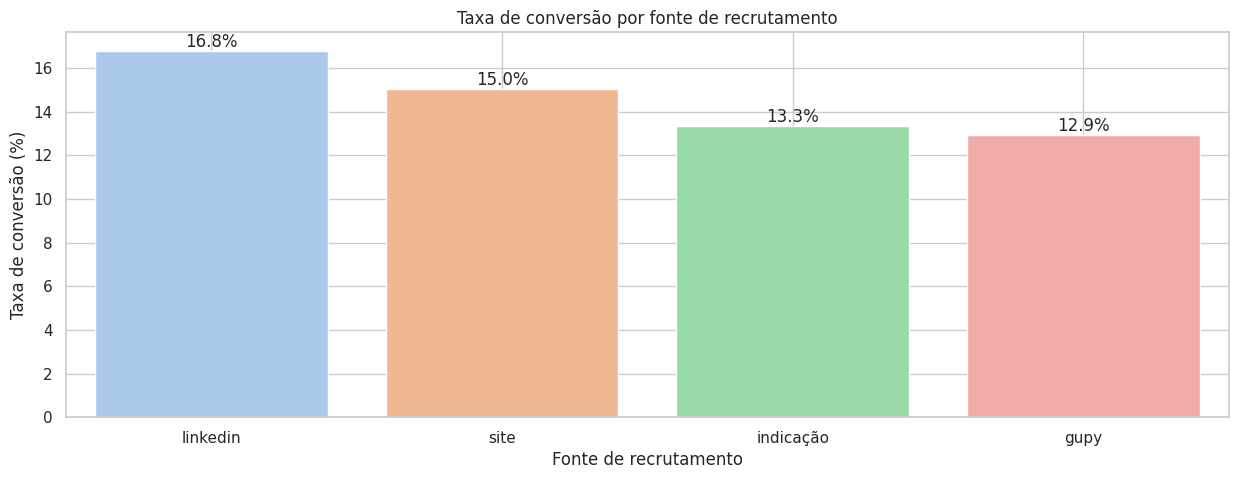

In [ ]:
plt.figure(figsize=(15,5))
ax = sns.barplot(x=taxa_conversao.index, y=taxa_conversao.values, hue=taxa_conversao.index, palette='pastel', legend=False)
plt.title('Taxa de conversão por fonte de recrutamento')
plt.xlabel('Fonte de recrutamento')
plt.ylabel('Taxa de conversão (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%')

plt.grid(True)
plt.show()

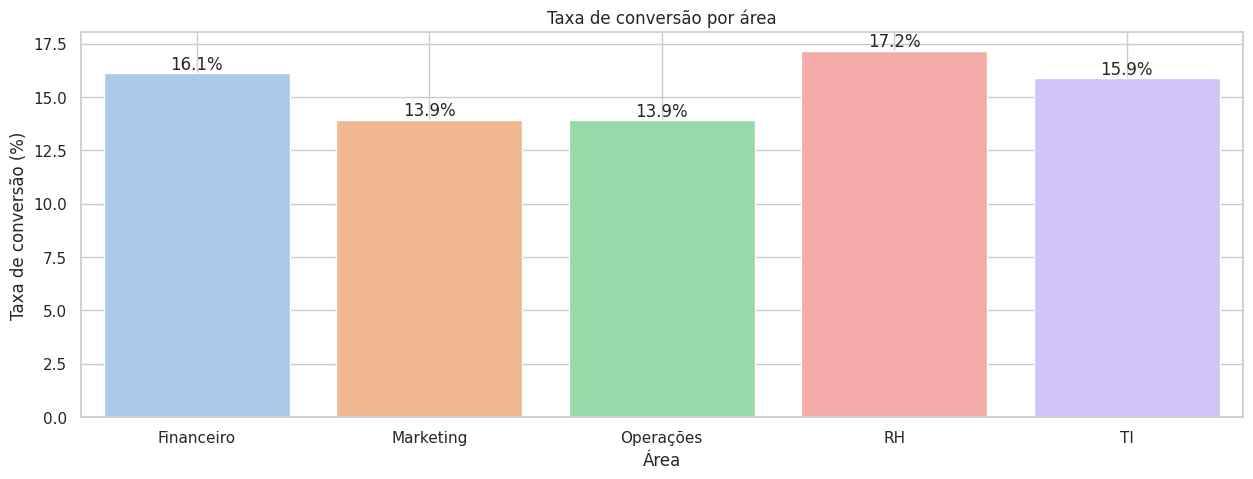

In [ ]:
plt.figure(figsize=(15,5))
ax = sns.barplot(x=taxa_conversao_area.index, y=taxa_conversao_area.values, hue=taxa_conversao_area.index, palette='pastel', legend=False)
plt.title('Taxa de conversão por área')
plt.xlabel('Área')
plt.ylabel('Taxa de conversão (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%')

plt.grid(True)
plt.show()

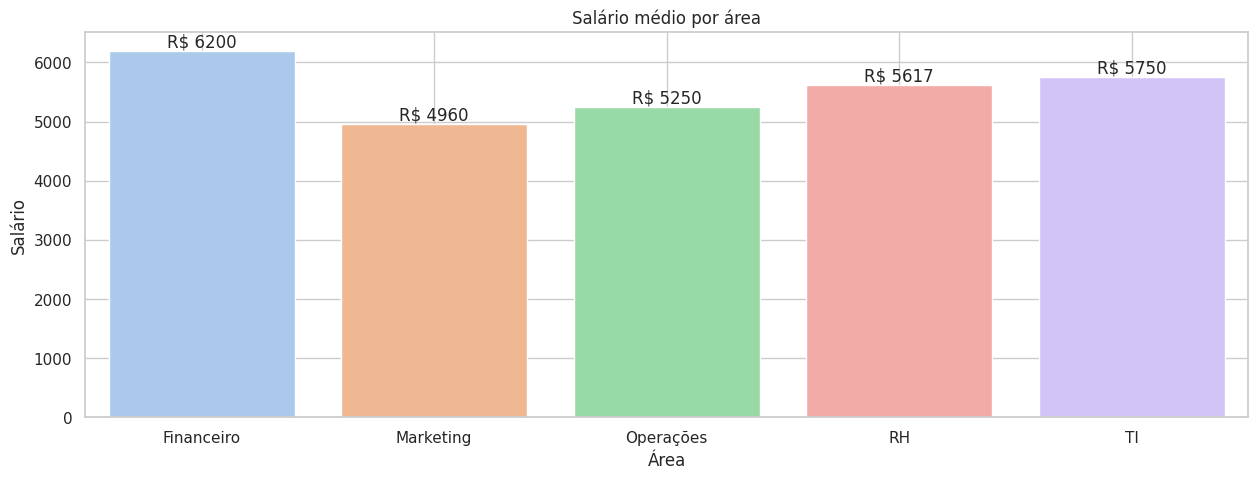

In [ ]:
plt.figure(figsize=(15,5))
ax = sns.barplot(x=area_salario.index, y=area_salario.values, hue=area_salario.index, palette='pastel', legend=False)
plt.title('Salário médio por área')
plt.xlabel('Área')
plt.ylabel('Salário')

for container in ax.containers:
    ax.bar_label(container, fmt='R$ %.0f')

plt.grid(True)
plt.show()

In [ ]:
taxa_conversao_genero_reset = taxa_conversao_genero.reset_index()

In [ ]:
taxa_conversao_genero_reset.head()

,area,genero,count
0,Financeiro,masculino,16.25
1,Financeiro,feminino,15.62
2,Marketing,masculino,13.88
3,Marketing,feminino,14.29
4,Operações,masculino,11.60


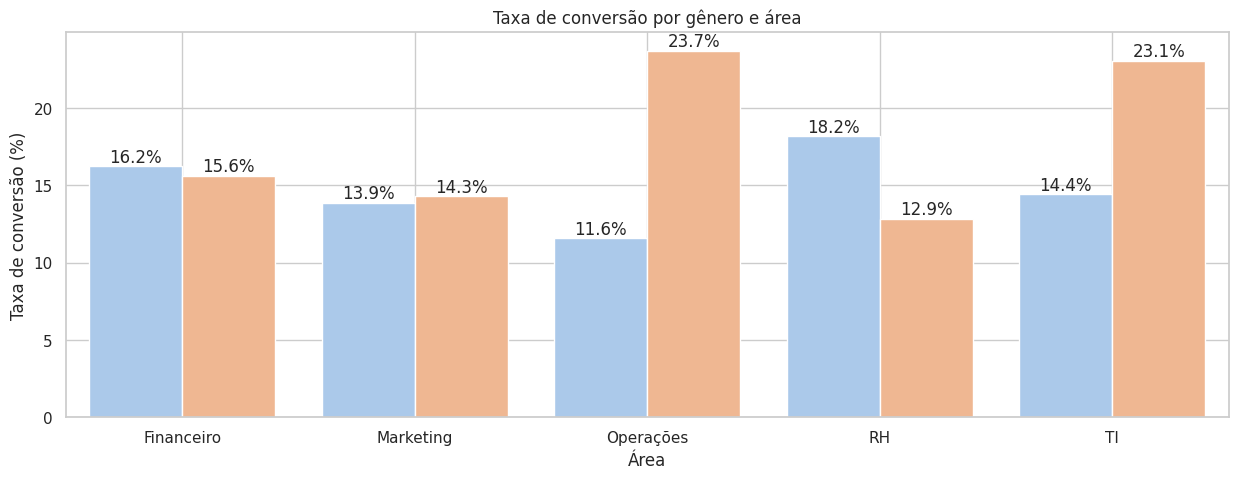

In [ ]:
plt.figure(figsize=(15,5))
ax = sns.barplot(data=taxa_conversao_genero_reset, x='area',y='count', hue='genero', palette='pastel', legend=False)
plt.title('Taxa de conversão por gênero e área')
plt.xlabel('Área')
plt.ylabel('Taxa de conversão (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%')

plt.grid(True)
plt.show()

In [ ]:
vagas_por_area_senioridade_reset = vagas.groupby(['area', 'senioridade']).size().reset_index()

In [ ]:
vagas_por_area_senioridade_reset.head()

,area,senioridade,0
0,Financeiro,Júnior,2
1,Financeiro,Pleno,2
2,Financeiro,Sênior,1
3,Marketing,Júnior,2
4,Marketing,Sênior,3


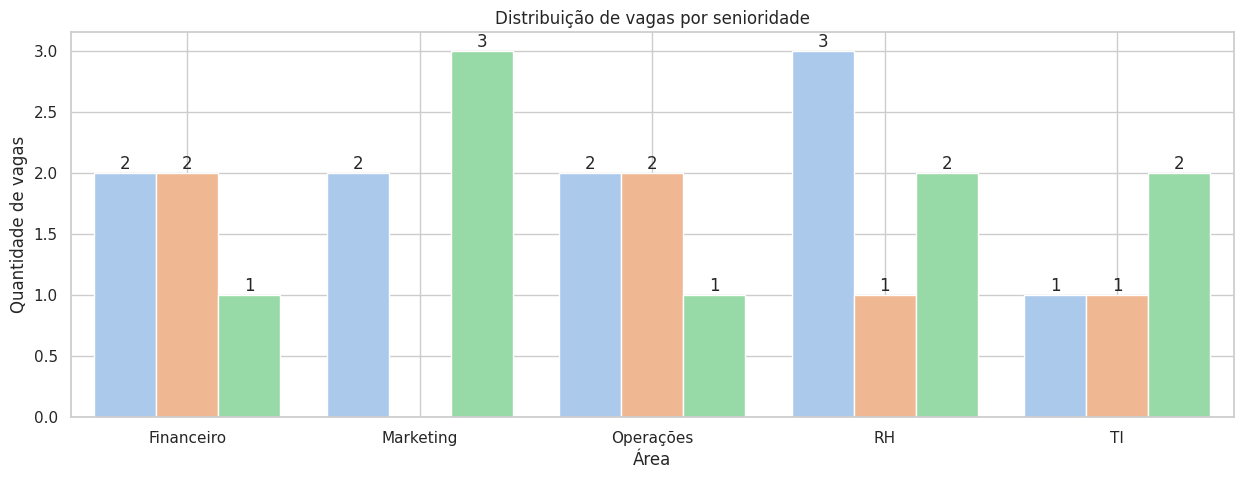

In [ ]:
plt.figure(figsize=(15,5))
ax = sns.barplot(data=vagas_por_area_senioridade_reset, x='area',y=0, hue='senioridade', palette='pastel', legend=False)
plt.title('Distribuição de vagas por senioridade')
plt.xlabel('Área')
plt.ylabel('Quantidade de vagas')

for container in ax.containers:
    ax.bar_label(container, fmt='%d')

plt.grid(True)
plt.show()